In [1]:
import numpy as np
import matplotlib.pyplot as plt
import jax
import jax.numpy as jnp

non-negative factorization

In [2]:
# initialize data
# initialize non-negative random vectors
length = 100
num_vectors = 100 # 100 samples
np.random.seed(0)
# initialize target matrix
W = np.abs(np.random.normal(0,1, size = (length, num_vectors)))

r = 10 # rank

In [6]:
@jax.jit
def loss(U,V):
    aprrox = U @ V
    MSE = jnp.mean((W-aprrox)**2)
    return MSE

loss_grad = jax.jit(jax.grad(loss, argnums=(0,1)))

In [7]:
# gradient descent initialization
U_init = np.abs(np.random.normal(0,1, size = (length, r)))
V_init = np.abs(np.random.normal(0,1, size = (r, num_vectors)))

In [13]:
U = U_init.copy()
V = V_init.copy()

niter = 1000
lr = 1
loss_history = []

for i in range(niter):
    grad_U, grad_V = loss_grad(U,V)
    U -= lr * grad_U
    V -= lr * grad_V

    U = np.maximum(U, 0)
    V = np.maximum(V, 0)

    current_loss = loss(U,V)
    loss_history.append(current_loss)

    if i % 100 == 0:
        print(f"iter {i}, loss {current_loss}")

iter 0, loss 21.31407356262207
iter 100, loss 0.45954182744026184
iter 200, loss 0.37429893016815186
iter 300, loss 0.3454672694206238
iter 400, loss 0.3312607705593109
iter 500, loss 0.32268771529197693
iter 600, loss 0.31671878695487976
iter 700, loss 0.3120841383934021
iter 800, loss 0.30821728706359863
iter 900, loss 0.3048350214958191


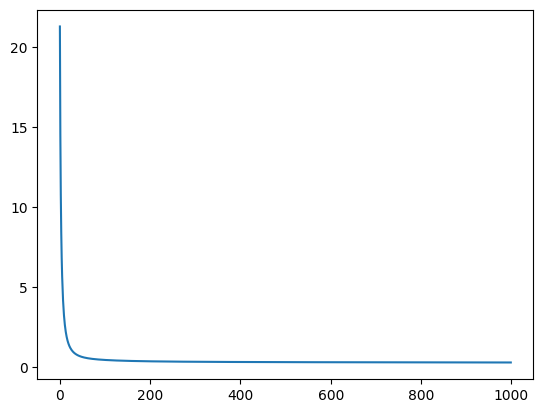

In [14]:
plt.plot(loss_history)